# Análise dos erros do sensor HC-SR04 — os erros são gaussianos?

Este notebook lê os arquivos `dado_experimental_Dcm.csv` gerados por `coleta_dados.py` e produz **todas as tabelas, figuras e números** do manuscrito.

**Como usar:** coloque este caderno na mesma pasta dos arquivos `.csv` e execute as células em ordem (*Executar tudo*).

**Convenções**
- $d$: distância real (informada, medida com a trena), em cm.
- $e = d_{\mathrm{med}} - d$: erro de cada leitura. A coleta grava o erro em cm; aqui ele é convertido para **mm**.
- Leituras sem eco aparecem como linhas vazias nos arquivos e são contadas como **perdas**.

**Arquivos gerados:** pasta `figuras/` (PDF), `tabela_resultados.tex`, `tabela_resultados_sem_outliers.tex`, `tabela_resultados.csv` e `resumo_analise.txt`.

## 1. Configuração

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ----------------------------- CONFIGURAÇÃO ---------------------------------
DADOS_DIR = "."            # pasta com os arquivos dado_experimental_Dcm.csv
FIG_DIR = "figuras"        # figuras em PDF (nomes esperados pelo manuscrito)
ALPHA = 0.05               # nível de significância dos testes
FATOR_IQR = 3.0            # outlier: além de 3 x IQR dos quartis (regra do boxplot)
N_SW_MAX = 5000            # Shapiro-Wilk usa no máximo 5000 pontos (subamostra)
SEMENTE = 42               # semente aleatória (resultados reproduzíveis)
DELTA_T_US = 1.0           # passo de tempo assumido do pulseIn (us)  <-- VERIFICAR
TEMPERATURA_C = 30.0       # a MESMA usada em coleta_dados.py
JANELA_SIGMA = 5           # janela dos histogramas: média ± 5 s
LAG_MAX = 20               # defasagens do gráfico de correlação
# -----------------------------------------------------------------------------

os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEMENTE)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
COR_DADOS, COR_GAUSS, COR_REF = "#4c78a8", "#d55e00", "#444444"

# velocidade do som e passo de distância do relógio do Arduino: Delta d = c * Delta t / 2
C_SOM = 331.0 + 0.6 * TEMPERATURA_C                      # m/s
DELTA_D_MM = C_SOM * DELTA_T_US * 1e-6 / 2 * 1e3         # mm
print(f"c = {C_SOM:.1f} m/s  ->  passo de discretização assumido: {DELTA_D_MM:.3f} mm")

c = 349.0 m/s  ->  passo de discretização assumido: 0.174 mm


## 2. Leitura dos arquivos

In [2]:
padrao = re.compile(r"^dado_experimental_([0-9]+(?:\.[0-9]+)?)cm\.csv$")
dados = {}
for caminho in sorted(glob.glob(os.path.join(DADOS_DIR, "dado_experimental_*cm.csv"))):
    nome = os.path.basename(caminho)
    m = padrao.match(nome)
    if m is None:
        print("ignorado (coleta incompleta ou nome fora do padrão):", nome)
        continue
    dados[float(m.group(1))] = pd.read_csv(caminho)

dists = sorted(dados)
if not dists:
    raise SystemExit("Nenhum arquivo dado_experimental_Dcm.csv encontrado em DADOS_DIR.")
print(f"{len(dists)} distâncias:", ", ".join(f"{d:g}" for d in dists), "cm")

# conferência: erro_cm deve ser medida_cm - d
for d in dists:
    df = dados[d]
    ok = df.dropna()
    dif = np.abs((ok["medida_cm"] - d) - ok["erro_cm"]).max() if len(ok) else 0.0
    if dif > 1e-3:
        print(f"ATENÇÃO: d = {d:g} cm -> erro_cm inconsistente (diferença máxima {dif:.4f} cm)")
print("conferência concluída.")
pd.DataFrame({"d (cm)": dists,
              "linhas": [len(dados[d]) for d in dists],
              "perdas": [int(dados[d]["erro_cm"].isna().sum()) for d in dists]}).set_index("d (cm)").T

4 distâncias: 5, 10, 15, 20 cm
conferência concluída.


d (cm),5.0,10.0,15.0,20.0
linhas,1000,1000,1000,1000
perdas,0,0,0,0


## 3. Estatísticas por distância

Para cada distância calculamos:
- **erro médio** $\bar e$ (o *viés*, erro sistemático) e **desvio padrão** $s$ (a dispersão);
- **assimetria** $g_1$ e **curtose em excesso** $g_2$ (ambas valem 0 para uma gaussiana);
- **teste de Shapiro–Wilk** ($H_0$: os erros vêm de uma distribuição normal). Se $p < 0{,}05$, rejeitamos $H_0$;
- o mesmo teste após somar a cada erro um **ruído uniforme** de largura $\Delta d$: se a rejeição some, a causa era a *discretização* do tempo do Arduino.

> **Atenção:** com $N = 10\,000$ os testes detectam desvios minúsculos. Olhe sempre $g_1$, $g_2$ e os gráficos antes de concluir.

In [3]:
def analisar(e, dd_mm):
    """Estatísticas de um conjunto de erros (mm), sem NaN."""
    e = np.asarray(e, float)
    n = e.size
    idx = np.arange(n) if n <= N_SW_MAX else rng.choice(n, N_SW_MAX, replace=False)
    e_ruido = e + rng.uniform(-dd_mm / 2, dd_mm / 2, n)
    s = e.std(ddof=1)
    return dict(N=n, media=e.mean(), s=s, u_media=s / np.sqrt(n), mediana=np.median(e),
                g1=stats.skew(e), g2=stats.kurtosis(e),
                SW_p=stats.shapiro(e[idx]).pvalue,
                SW_p_com_ruido=stats.shapiro(e_ruido[idx]).pvalue)

def sem_outliers(e, fator=FATOR_IQR):
    q1, q3 = np.percentile(e, [25, 75])
    iqr = q3 - q1
    return (e >= q1 - fator * iqr) & (e <= q3 + fator * iqr)

E_ts = {}      # série temporal completa (mm), com NaN nas perdas
E = {}         # erros válidos (mm)
E_so = {}      # erros válidos sem outliers (mm)
lin, lin_so = [], []

for d in dists:
    e_ts = dados[d]["erro_cm"].to_numpy(float) * 10.0
    valido = ~np.isnan(e_ts)
    e = e_ts[valido]
    keep = sem_outliers(e)
    E_ts[d], E[d], E_so[d] = e_ts, e, e[keep]

    r = analisar(e, DELTA_D_MM)
    r.update(d_cm=d, linhas=len(e_ts), perdas=int((~valido).sum()), removidos=0)
    lin.append(r)

    r2 = analisar(E_so[d], DELTA_D_MM)
    r2.update(d_cm=d, linhas=len(e_ts), perdas=int((~valido).sum()), removidos=int((~keep).sum()))
    lin_so.append(r2)

cols = ["d_cm", "linhas", "perdas", "removidos", "N", "media", "u_media", "s", "mediana",
        "g1", "g2", "SW_p", "SW_p_com_ruido"]
res = pd.DataFrame(lin)[cols]
res_so = pd.DataFrame(lin_so)[cols]

# regra prática DIDÁTICA (ajuste e justifique): p grande -> compatível; p pequeno mas g1, g2 pequenos -> desvio pequeno
LIM_G1, LIM_G2 = 0.2, 0.5
def classificar(r):
    if r.SW_p >= ALPHA:
        return "compatível com gaussiana"
    if abs(r.g1) < LIM_G1 and abs(r.g2) < LIM_G2:
        return "rejeita, mas desvio pequeno"
    return "não gaussiana"
res["classificacao"] = res.apply(classificar, axis=1)

res.round({"media": 3, "u_media": 3, "s": 3, "mediana": 3, "g1": 3, "g2": 3, "SW_p": 4, "SW_p_com_ruido": 4})

,d_cm,linhas,perdas,removidos,N,media,u_media,s,mediana,g1,g2,SW_p,SW_p_com_ruido,classificacao
0,5.0,1000,0,0,1000,-2.344,0.015,0.464,-2.079,-1.027,-0.881,0.0,0.0,não gaussiana
1,10.0,1000,0,0,1000,-5.270,0.018,0.579,-5.715,1.247,7.001,0.0,0.0,não gaussiana
2,15.0,1000,0,0,1000,-7.593,0.024,0.756,-7.794,3.978,19.695,0.0,0.0,não gaussiana
3,20.0,1000,0,0,1000,-1.803,0.064,2.014,-2.953,0.874,-1.027,0.0,0.0,não gaussiana


In [4]:
n_rej = int((res.SW_p < ALPHA).sum())
n_rej_ruido = int((res.SW_p_com_ruido < ALPHA).sum())
p_alguma = 1 - (1 - ALPHA) ** len(dists)
print(f"Rejeições de H0 (p < {ALPHA}): {n_rej} de {len(dists)} distâncias "
      f"({n_rej_ruido} após o ruído uniforme).")
print(f"Se H0 valesse em TODAS, esperaríamos ~{ALPHA * len(dists):.1f} rejeições por acaso; "
      f"a chance de pelo menos uma é {100 * p_alguma:.0f}%.")
print("Isso significa: poucas rejeições isoladas e com p perto de 0,05 pesam pouco; "
      "rejeições em muitas distâncias, com p muito pequeno e desvios claros nos gráficos, pesam muito.")
res[["d_cm", "SW_p", "SW_p_com_ruido", "g1", "g2", "classificacao"]].round(4)

Rejeições de H0 (p < 0.05): 4 de 4 distâncias (4 após o ruído uniforme).
Se H0 valesse em TODAS, esperaríamos ~0.2 rejeições por acaso; a chance de pelo menos uma é 19%.
Isso significa: poucas rejeições isoladas e com p perto de 0,05 pesam pouco; rejeições em muitas distâncias, com p muito pequeno e desvios claros nos gráficos, pesam muito.


,d_cm,SW_p,SW_p_com_ruido,g1,g2,classificacao
0,5.0,0.0,0.0,-1.0267,-0.8812,não gaussiana
1,10.0,0.0,0.0,1.2465,7.0013,não gaussiana
2,15.0,0.0,0.0,3.9784,19.6949,não gaussiana
3,20.0,0.0,0.0,0.8742,-1.0269,não gaussiana


### Discretização do relógio do Arduino

O Arduino mede o tempo em passos; cada passo vira um passo de distância $\Delta d = c\,\Delta t/2$. Abaixo, comparamos o passo **assumido** com o menor degrau **observado** nos dados. Se o degrau observado for bem diferente, ajuste `DELTA_T_US` na configuração (e confirme com um sinal de referência).

In [5]:
passos = []
for d in dists:
    v = np.unique(np.round(dados[d]["medida_cm"].dropna().to_numpy() * 10, 4))   # mm
    dif = np.diff(v)
    dif = dif[dif > 1e-3]
    passos.append(dif.min() if dif.size else np.nan)
print(f"Passo assumido (Delta t = {DELTA_T_US:g} us): {DELTA_D_MM:.3f} mm")
print(f"Menor degrau observado nos dados: mediana entre distâncias = {np.nanmedian(passos):.3f} mm")
print(f"Razão passo / desvio padrão (mediana): {DELTA_D_MM / res.s.median():.3f}  "
      "(bem menor que 1 -> discretização desprezível)")

Passo assumido (Delta t = 1 us): 0.174 mm
Menor degrau observado nos dados: mediana entre distâncias = 0.173 mm
Razão passo / desvio padrão (mediana): 0.261  (bem menor que 1 -> discretização desprezível)


## 4. Viés e dispersão em função da distância

Uma reta ajustada a $\bar e(d)$ mostra se o viés cresce com a distância (inclinação) ou se é um deslocamento constante (intercepto), que pode vir de um **plano de referência** mal definido. Outra reta ajustada a $s(d)$ mostra se a dispersão cresce com $d$.

Viés:      inclinação = -0.0140 mm/cm (p = 0.967), intercepto = -4.077 mm
Dispersão: inclinação = +0.0966 mm/cm (p = 0.131), intercepto = -0.254 mm


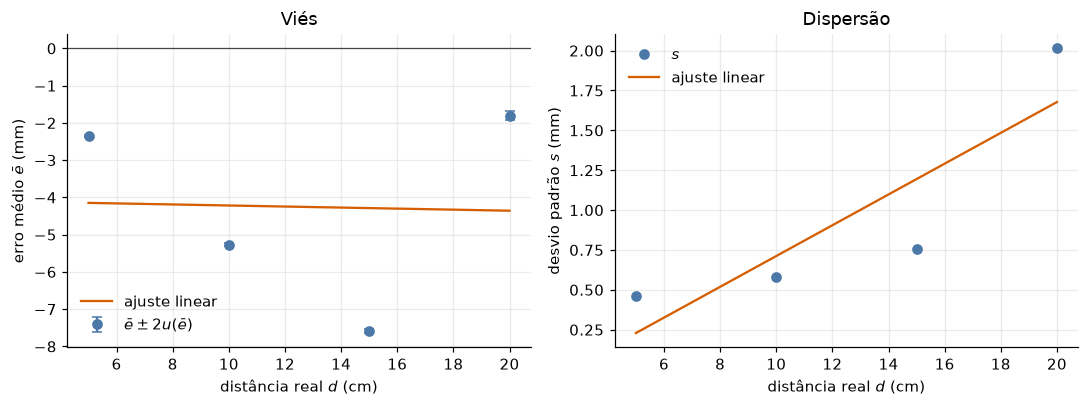

In [6]:
reg_vies = stats.linregress(res.d_cm, res.media)
reg_disp = stats.linregress(res.d_cm, res.s)
print(f"Viés:      inclinação = {reg_vies.slope:+.4f} mm/cm (p = {reg_vies.pvalue:.3g}), "
      f"intercepto = {reg_vies.intercept:+.3f} mm")
print(f"Dispersão: inclinação = {reg_disp.slope:+.4f} mm/cm (p = {reg_disp.pvalue:.3g}), "
      f"intercepto = {reg_disp.intercept:+.3f} mm")

x = np.linspace(res.d_cm.min(), res.d_cm.max(), 50)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].errorbar(res.d_cm, res.media, yerr=2 * res.u_media, fmt="o", color=COR_DADOS, capsize=3,
               label=r"$\bar{e} \pm 2u(\bar{e})$")
ax[0].plot(x, reg_vies.intercept + reg_vies.slope * x, color=COR_GAUSS, label="ajuste linear")
ax[0].axhline(0, color=COR_REF, lw=0.8)
ax[0].set(xlabel="distância real $d$ (cm)", ylabel="erro médio $\\bar{e}$ (mm)", title="Viés")
ax[0].legend(frameon=False)
ax[1].plot(res.d_cm, res.s, "o", color=COR_DADOS, label="$s$")
ax[1].plot(x, reg_disp.intercept + reg_disp.slope * x, color=COR_GAUSS, label="ajuste linear")
ax[1].set(xlabel="distância real $d$ (cm)", ylabel="desvio padrão $s$ (mm)", title="Dispersão")
ax[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_erro_vs_distancia.pdf", bbox_inches="tight")
plt.show()

## 5. Forma da distribuição: histogramas e gráficos Q-Q

**Histograma:** as barras são os dados; a curva laranja é a gaussiana com a mesma média e o mesmo desvio padrão. Pontos fora da janela ($\pm 5s$) não aparecem, mas estão contados no título.

**Gráfico Q-Q:** se os pontos ficarem sobre a reta, a distribuição é compatível com a gaussiana. Curvas nas pontas indicam caudas diferentes das da gaussiana.

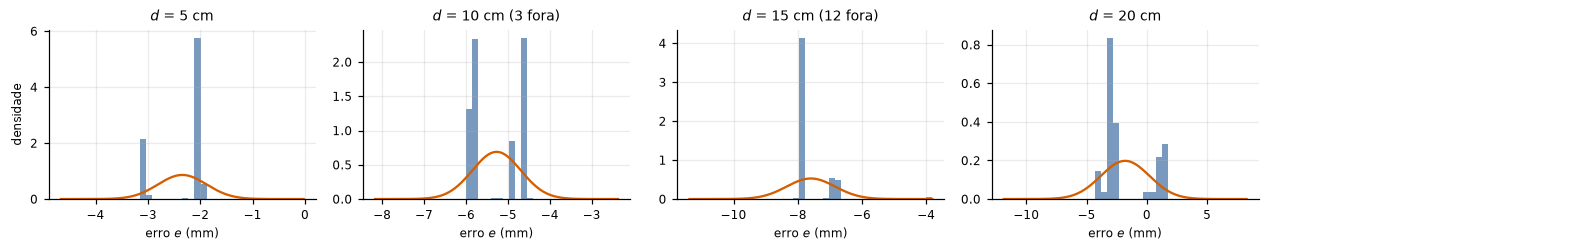

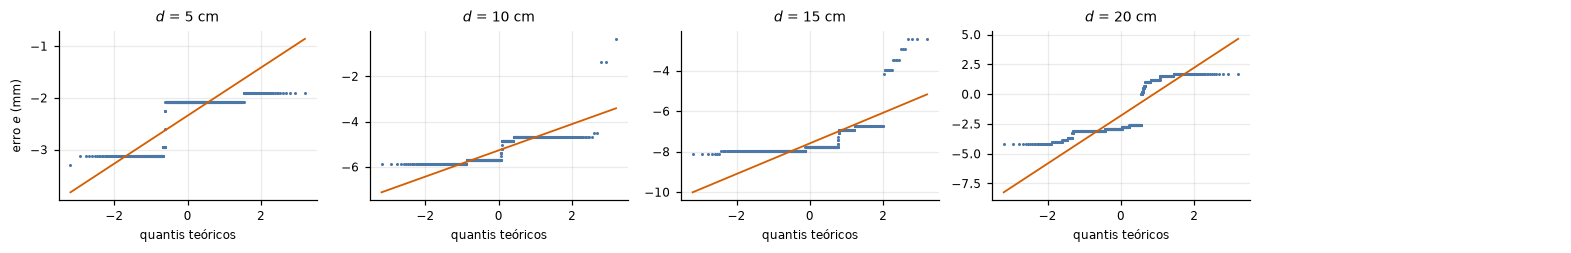

In [7]:
def grade(n, ncols=5, w=2.9, h=2.4):
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h), squeeze=False)
    for ax in axs.flat[n:]:
        ax.axis("off")
    return fig, axs.flat, nrows, ncols

# ------------------------------ histogramas ---------------------------------
fig, axs, nrows, ncols = grade(len(dists))
for k, (d, ax) in enumerate(zip(dists, axs)):
    e = E[d]; m, s = e.mean(), e.std(ddof=1)
    bins = np.linspace(m - JANELA_SIGMA * s, m + JANELA_SIGMA * s, 41)
    fora = int(((e < bins[0]) | (e > bins[-1])).sum())
    ax.hist(e, bins=bins, density=True, color=COR_DADOS, alpha=0.75)
    xs = np.linspace(bins[0], bins[-1], 300)
    ax.plot(xs, stats.norm.pdf(xs, m, s), color=COR_GAUSS, lw=1.5)
    ax.set_title(f"$d$ = {d:g} cm" + (f" ({fora} fora)" if fora else ""), fontsize=9)
    ax.tick_params(labelsize=8)
    if k // ncols == nrows - 1 or k + ncols >= len(dists):
        ax.set_xlabel("erro $e$ (mm)", fontsize=8)
    if k % ncols == 0:
        ax.set_ylabel("densidade", fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_histogramas.pdf", bbox_inches="tight")
plt.show()

# ------------------------------- gráficos Q-Q --------------------------------
fig, axs, nrows, ncols = grade(len(dists))
for k, (d, ax) in enumerate(zip(dists, axs)):
    e = E[d]; m, s = e.mean(), e.std(ddof=1)
    osm, osr = stats.probplot(e, dist="norm", fit=False)
    ax.plot(osm, osr, ".", ms=2, color=COR_DADOS, rasterized=True)
    ax.plot([osm[0], osm[-1]], [m + s * osm[0], m + s * osm[-1]], color=COR_GAUSS, lw=1.2)
    ax.set_title(f"$d$ = {d:g} cm", fontsize=9)
    ax.tick_params(labelsize=8)
    if k // ncols == nrows - 1 or k + ncols >= len(dists):
        ax.set_xlabel("quantis teóricos", fontsize=8)
    if k % ncols == 0:
        ax.set_ylabel("erro $e$ (mm)", fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_qq.pdf", bbox_inches="tight")
plt.show()

## 6. Independência das leituras

Se as leituras forem independentes, a correlação entre uma leitura e a seguinte (e entre leituras mais distantes) fica dentro de $\pm 1{,}96/\sqrt{N}$. Mostramos a série temporal e a correlação para três distâncias representativas (a menor, uma intermediária e a maior). Na tabela, a correlação com a leitura seguinte ($r_1$) de **todas** as distâncias.

> Neste experimento a temperatura não é gravada junto com cada leitura (usa-se um valor fixo em `coleta_dados.py`). Anote a temperatura da sala no início e no fim de cada coleta; se ela variou, discuta o efeito de ≈ 1,7 mm por °C a 1 m.

Distâncias com |r1| acima de 1,96/sqrt(N): 4 de 4 (esperado por acaso: ~0.2)


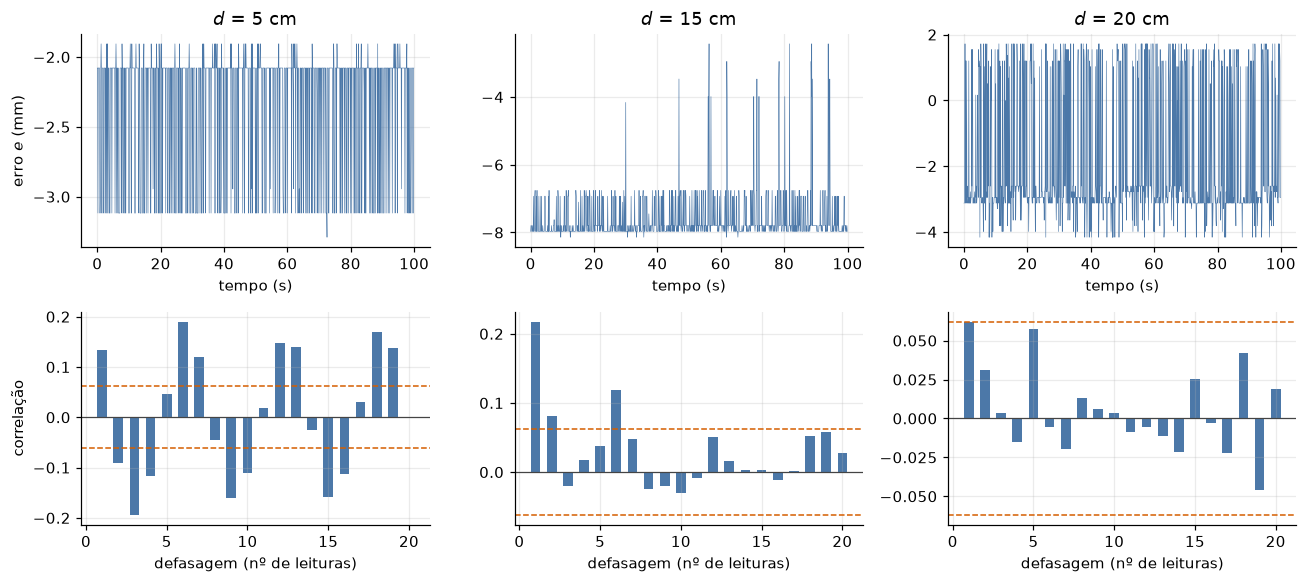

,d_cm,r1,limite_r,r1_fora
0,5.0,0.1330,0.062,True
1,10.0,0.0821,0.062,True
2,15.0,0.2177,0.062,True
3,20.0,0.0622,0.062,True


In [8]:
def acf(e_ts, lag_max=LAG_MAX):
    s = pd.Series(e_ts)
    return np.array([s.autocorr(lag=k) for k in range(1, lag_max + 1)])

res["r1"] = [pd.Series(E_ts[d]).autocorr(lag=1) for d in dists]
res["limite_r"] = 1.96 / np.sqrt(res.N)
res["r1_fora"] = res.r1.abs() > res.limite_r
print(f"Distâncias com |r1| acima de 1,96/sqrt(N): {int(res.r1_fora.sum())} de {len(dists)} "
      f"(esperado por acaso: ~{0.05 * len(dists):.1f})")

rep = [dists[0], dists[len(dists) // 2], dists[-1]]
fig, ax = plt.subplots(2, 3, figsize=(12, 5.4))
for j, d in enumerate(rep):
    e_ts = E_ts[d]; n_ok = int(np.sum(~np.isnan(e_ts)))
    t = np.arange(len(e_ts)) * 0.1
    ax[0, j].plot(t, e_ts, lw=0.4, color=COR_DADOS)
    ax[0, j].set(title=f"$d$ = {d:g} cm", xlabel="tempo (s)")
    if j == 0:
        ax[0, j].set_ylabel("erro $e$ (mm)")
    a = acf(e_ts)
    lim = 1.96 / np.sqrt(n_ok)
    ax[1, j].bar(np.arange(1, LAG_MAX + 1), a, color=COR_DADOS, width=0.6)
    ax[1, j].axhline(lim, color=COR_GAUSS, ls="--", lw=1)
    ax[1, j].axhline(-lim, color=COR_GAUSS, ls="--", lw=1)
    ax[1, j].axhline(0, color=COR_REF, lw=0.8)
    ax[1, j].set(xlabel="defasagem (nº de leituras)")
    if j == 0:
        ax[1, j].set_ylabel("correlação")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_serie_acf.pdf", bbox_inches="tight")
plt.show()
res[["d_cm", "r1", "limite_r", "r1_fora"]].round(4)

## 7. Visão global: erros padronizados

Padronizamos os erros de cada distância, $z = (e-\bar e)/s$, e juntamos todos. Se os erros fossem gaussianos em todas as distâncias, $z$ seguiria a gaussiana padrão: **4,55 %** dos pontos com $|z|>2$ e **0,27 %** com $|z|>3$.

4000 erros padronizados:  |z|>2: 0.65% (esperado 4,55%)   |z|>3: 0.62% (esperado 0,27%)
assimetria = +1.268   curtose em excesso = +6.197


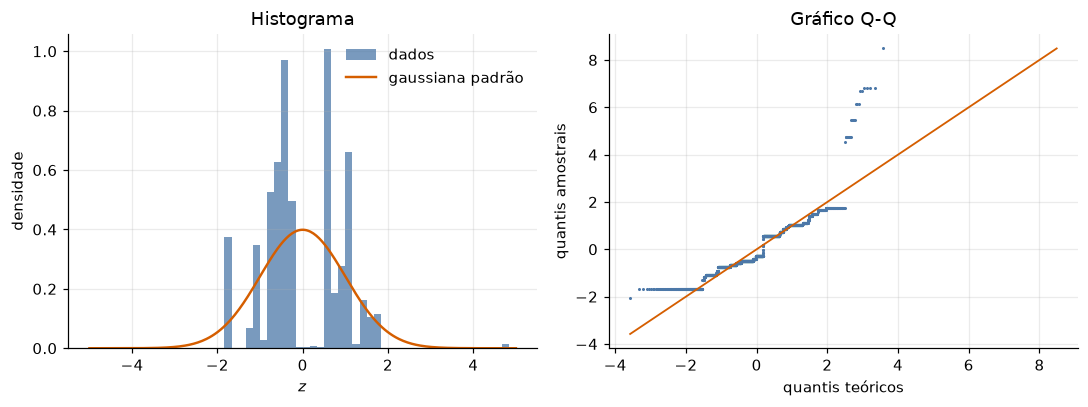

In [9]:
z = np.concatenate([(E[d] - E[d].mean()) / E[d].std(ddof=1) for d in dists])
f2, f3 = np.mean(np.abs(z) > 2), np.mean(np.abs(z) > 3)
print(f"{z.size} erros padronizados:  |z|>2: {100 * f2:.2f}% (esperado 4,55%)   "
      f"|z|>3: {100 * f3:.2f}% (esperado 0,27%)")
print(f"assimetria = {stats.skew(z):+.3f}   curtose em excesso = {stats.kurtosis(z):+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
bins = np.linspace(-5, 5, 61)
ax[0].hist(z, bins=bins, density=True, color=COR_DADOS, alpha=0.75, label="dados")
xs = np.linspace(-5, 5, 300)
ax[0].plot(xs, stats.norm.pdf(xs), color=COR_GAUSS, lw=1.6, label="gaussiana padrão")
ax[0].set(xlabel="$z$", ylabel="densidade", title="Histograma")
ax[0].legend(frameon=False)
osm, osr = stats.probplot(z, dist="norm", fit=False)
ax[1].plot(osm, osr, ".", ms=2, color=COR_DADOS, rasterized=True)
lim = [min(osm[0], osr[0]), max(osm[-1], osr[-1])]
ax[1].plot(lim, lim, color=COR_GAUSS, lw=1.2)
ax[1].set(xlabel="quantis teóricos", ylabel="quantis amostrais", title="Gráfico Q-Q")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_agregado.pdf", bbox_inches="tight")
plt.show()

## 8. Efeito dos *outliers*

*Outlier* aqui é um erro além de $3\times$IQR dos quartis (a regra do diagrama de caixa). Repetimos as estatísticas sem eles e comparamos: se as conclusões mudam, os *outliers* (ecos esporádicos, reflexões) estão dominando a forma da distribuição.

In [10]:
comp = pd.DataFrame({"d_cm": res.d_cm, "removidos": res_so.removidos,
                     "s": res.s, "s_sem": res_so.s,
                     "g2": res.g2, "g2_sem": res_so.g2,
                     "SW_p": res.SW_p, "SW_p_sem": res_so.SW_p})
print(f"Total de outliers removidos: {int(res_so.removidos.sum())} "
      f"({100 * res_so.removidos.sum() / res.N.sum():.3f}% das leituras válidas)")
print(f"Rejeições de H0 sem outliers: {int((res_so.SW_p < ALPHA).sum())} de {len(dists)} "
      f"(com outliers: {n_rej}).")
comp.round(4)

Total de outliers removidos: 220 (5.500% das leituras válidas)
Rejeições de H0 sem outliers: 4 de 4 (com outliers: 4).


,d_cm,removidos,s,s_sem,g2,g2_sem,SW_p,SW_p_sem
0,5.0,0,0.4636,0.4636,-0.8812,-0.8812,0.0,0.0
1,10.0,3,0.5795,0.5312,7.0013,-1.8911,0.0,0.0
2,15.0,217,0.7563,0.0945,19.6949,1.9236,0.0,0.0
3,20.0,0,2.0140,2.0140,-1.0269,-1.0269,0.0,0.0


## 9. Tabelas para o manuscrito (LaTeX) e resumo em texto

In [11]:
def num(x, nd=2):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "--"
    return "$" + f"{x:.{nd}f}".replace(".", "{,}") + "$"

def pval(p):
    return r"$<\!10^{-4}$" if p < 1e-4 else num(p, 3)

def tabela_latex(df, legenda, rotulo, arquivo, titulo_col3):
    cab = [r"$d$ (cm)", r"$N$", titulo_col3, r"$\bar{e}$ (mm)", r"$s$ (mm)",
           r"$g_1$", r"$g_2$", r"$p_{\mathrm{SW}}$", r"$p_{\mathrm{SW}}^{\,\text{ruído}}$"]
    L = [r"\begin{table}[htbp]", r"\centering", r"\small", r"\setlength{\tabcolsep}{4pt}",
         r"\caption{" + legenda + r"}\label{" + rotulo + "}",
         r"\begin{tabular}{rrrrrrrrr}", r"\toprule", " & ".join(cab) + r" \\", r"\midrule"]
    for r in df.itertuples():
        col3 = r.perdas if titulo_col3 == "perdas" else r.removidos
        L.append(" & ".join([f"{r.d_cm:g}", f"{int(r.N)}", f"{int(col3)}",
                             num(r.media, 2), num(r.s, 2), num(r.g1, 2), num(r.g2, 2),
                             pval(r.SW_p), pval(r.SW_p_com_ruido)]) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    with open(arquivo, "w", encoding="utf-8") as f:
        f.write("\n".join(L) + "\n")

tabela_latex(res,
    r"Resultados por distância real $d$: leituras válidas $N$, perdas de eco, erro médio $\bar{e}$, desvio padrão $s$, "
    r"assimetria $g_1$, curtose em excesso $g_2$ e valor $p$ do teste de Shapiro--Wilk sem e com ruído uniforme "
    r"de largura $\Delta d$ (ver texto).",
    "tab:res", "tabela_resultados.tex", "perdas")
tabela_latex(res_so,
    r"Mesmas grandezas da Tabela~\ref{tab:res} após remover \emph{outliers} (além de $3\times$IQR dos quartis).",
    "tab:res_sem", "tabela_resultados_sem_outliers.tex", "removidos")

res.to_csv("tabela_resultados.csv", index=False, float_format="%.6g")

L = []
L.append("RESUMO DA ANÁLISE — HC-SR04")
L.append("=" * 60)
L.append(f"Distâncias: {len(dists)} ({dists[0]:g} a {dists[-1]:g} cm)")
L.append(f"Leituras válidas: {int(res.N.sum())} | perdas de eco: {int(res.perdas.sum())} "
         f"({100 * res.perdas.sum() / res.linhas.sum():.2f}%)")
L.append(f"Erro médio (viés): de {res.media.min():+.3f} a {res.media.max():+.3f} mm")
L.append(f"Desvio padrão: de {res.s.min():.3f} a {res.s.max():.3f} mm")
L.append(f"Regressão do viés: inclinação {reg_vies.slope:+.4f} mm/cm (p={reg_vies.pvalue:.3g}); intercepto {reg_vies.intercept:+.3f} mm")
L.append(f"Regressão da dispersão: inclinação {reg_disp.slope:+.4f} mm/cm (p={reg_disp.pvalue:.3g}); intercepto {reg_disp.intercept:+.3f} mm")
L.append(f"Passo de discretização assumido: {DELTA_D_MM:.3f} mm (razão passo/s mediana = {DELTA_D_MM / res.s.median():.3f})")
L.append(f"Shapiro-Wilk (p<{ALPHA}): {n_rej}/{len(dists)} rejeições; com ruído uniforme: {n_rej_ruido}/{len(dists)}; sem outliers: {int((res_so.SW_p < ALPHA).sum())}/{len(dists)}")
L.append(f"Chance de >=1 rejeição espúria se H0 valesse sempre: {100 * p_alguma:.0f}%")
L.append(f"Assimetria g1: {res.g1.min():+.3f} a {res.g1.max():+.3f} | curtose g2: {res.g2.min():+.3f} a {res.g2.max():+.3f}")
L.append(f"Correlação lag-1 fora de ±1,96/sqrt(N): {int(res.r1_fora.sum())}/{len(dists)} distâncias")
L.append(f"Erros padronizados ({z.size}): |z|>2: {100 * f2:.2f}% (esp. 4,55%) | |z|>3: {100 * f3:.2f}% (esp. 0,27%)")
L.append(f"Outliers removidos (3xIQR): {int(res_so.removidos.sum())} ({100 * res_so.removidos.sum() / res.N.sum():.3f}%)")
L.append("")
L.append("Classificação por distância (regra prática didática, ver notebook):")
for r in res.itertuples():
    L.append(f"  d = {r.d_cm:>6g} cm  p_SW = {r.SW_p:.4f}  g1 = {r.g1:+.2f}  g2 = {r.g2:+.2f}  -> {r.classificacao}")
with open("resumo_analise.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(L) + "\n")
print("\n".join(L))
print("\nArquivos gerados:", ", ".join(sorted(os.listdir(FIG_DIR))),
      "| tabela_resultados.tex | tabela_resultados_sem_outliers.tex | tabela_resultados.csv | resumo_analise.txt")

RESUMO DA ANÁLISE — HC-SR04
Distâncias: 4 (5 a 20 cm)
Leituras válidas: 4000 | perdas de eco: 0 (0.00%)
Erro médio (viés): de -7.593 a -1.803 mm
Desvio padrão: de 0.464 a 2.014 mm
Regressão do viés: inclinação -0.0140 mm/cm (p=0.967); intercepto -4.077 mm
Regressão da dispersão: inclinação +0.0966 mm/cm (p=0.131); intercepto -0.254 mm
Passo de discretização assumido: 0.174 mm (razão passo/s mediana = 0.261)
Shapiro-Wilk (p<0.05): 4/4 rejeições; com ruído uniforme: 4/4; sem outliers: 4/4
Chance de >=1 rejeição espúria se H0 valesse sempre: 19%
Assimetria g1: -1.027 a +3.978 | curtose g2: -1.027 a +19.695
Correlação lag-1 fora de ±1,96/sqrt(N): 4/4 distâncias
Erros padronizados (4000): |z|>2: 0.65% (esp. 4,55%) | |z|>3: 0.62% (esp. 0,27%)
Outliers removidos (3xIQR): 220 (5.500%)

Classificação por distância (regra prática didática, ver notebook):
  d =      5 cm  p_SW = 0.0000  g1 = -1.03  g2 = -0.88  -> não gaussiana
  d =     10 cm  p_SW = 0.0000  g1 = +1.25  g2 = +7.00  -> não gaussia

## 10. Perguntas para discussão

1. Os erros têm **viés**? Ele depende da distância ou é um deslocamento constante (plano de referência)?
2. A dispersão $s$ cresce com a distância? Compare com os 3 mm citados para o sensor.
3. Em quantas distâncias o teste rejeita a gaussiana? Isso é mais do que o acaso explicaria?
4. A rejeição sobrevive ao **ruído uniforme** (discretização) e à remoção de ***outliers***?
5. Que forma têm as caudas ($g_2$) e a assimetria ($g_1$)? Há picos secundários nos histogramas?
6. As leituras são independentes? O que isso muda na interpretação do erro padrão da média?
7. O que mudaria se cada ponto fosse a **média de 16 leituras**? (Teste no caderno, agrupando os erros de 16 em 16.)